In [1]:
# ============================================================
# FedMIA Attack Pipeline
# Dataset: eICU
# Setting: Federated Learning (IID Clients)
# Model: MLP
# ============================================================

# -----------------------------
# PART 1: Load FL Artifacts
# -----------------------------
# Load saved artifacts from federated training notebook:
# - clients_scaled
# - X_test_scaled
# - y_test_global
# - all_round_global_weights_before
# - all_round_global_weights
# - all_round_local_weights

# -----------------------------
# PART 2: Define Attack Setup
# -----------------------------
# Select target client (victim client)
# Example:
# target_client = 50

# Members:
# Samples from target client's training data

# Non-members:
# Samples from global test set
# (In previous notebook: target client test set)

# -----------------------------
# PART 3: Sample Attack Patients
# -----------------------------
# Randomly sample:
# - 500 member patients
# - 500 non-member patients

# Store:
# - member_samples
# - member_labels
# - nonmember_samples
# - nonmember_labels

# -----------------------------
# PART 4: Define Attack Model
# -----------------------------
# Rebuild same MLP architecture used in FL training.

# -----------------------------
# PART 5: FedMIA-I
# -----------------------------
# Step 1:
# Compute patient loss on one client model.

# Step 2:
# For one patient and one round:
# Evaluate patient on all client local models.

# Step 3:
# Compute FedMIA score:
#
# score = (mean(reference_losses) - target_loss)
#         / std(reference_losses)
#
# where:
# target_loss = loss on target client model
# reference_losses = losses on all other client models

# Step 4:
# Compute single-round attack score for:
# - all members
# - all non-members

# Step 5:
# Multi-round FedMIA-I:
# Compute score for each round (20 rounds)
# Then average scores across rounds.
#
# final_score = mean(round_scores)

# Step 6:
# Compute attack ROC-AUC

# -----------------------------
# PART 6: FedMIA-II
# -----------------------------
# Step 1:
# Select target round

# Step 2:
# Compute client update:
#
# client_update =
# local_weights - global_weights_before_round

# Step 3:
# Compute patient gradient
# using one forward + backward pass

# Step 4:
# Flatten both vectors:
# - client update
# - patient gradient

# Step 5:
# Compute cosine similarity:
#
# similarity =
# cosine(patient_gradient, client_update)

# Step 6:
# Compute similarity for:
# - members
# - non-members

# Step 7:
# Multi-round FedMIA-II:
# Average similarities across rounds

# Step 8:
# Compute attack ROC-AUC

# -----------------------------
# PART 7: Final Comparison
# -----------------------------
# Compare:
# - FedMIA-I Attack AUC
# - FedMIA-II Attack AUC
#
# Expected:
# FedMIA-II > FedMIA-I
# ============================================================

In [2]:
# Load the whole federeted setup

import pickle

with open("fl_artifacts.pkl", "rb") as f:
    artifacts = pickle.load(f)

clients_scaled = artifacts["clients_scaled"]
clients = artifacts["clients"]
X_test_scaled = artifacts["X_test_scaled"]
y_test_global = artifacts["y_test_global"]
all_round_global_weights_before = artifacts["all_round_global_weights_before"]
all_round_global_weights = artifacts["all_round_global_weights"]
all_round_local_weights = artifacts["all_round_local_weights"]

In [3]:
print(len(all_round_global_weights))
print(len(all_round_local_weights))
print(len(all_round_local_weights[0]))

20
20
50


In [4]:
print(list(clients_scaled.keys())[:10])
print(max(clients_scaled.keys()))

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
50


In [5]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import classification_report, f1_score
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

## FedMIA-I Pipeline

# Step 1 — Create evaluation set

In [6]:
# considering target client 50

target_client = 50

member_X = clients_scaled[target_client]['X']
member_y = clients_scaled[target_client]['y']

nonmember_X = X_test_scaled
nonmember_y = y_test_global.values

In [7]:
print(member_X.shape)
print(nonmember_X.shape)

(2120, 445)
(26507, 445)


# Step 2: Sample Attack Patients

Patient

   ↓
   
Reference distribution from other clients

   ↓
   
FedMIA score

   ↓
   
Collect scores for members + non-members

   ↓
   
ROC-AUC

In [8]:
np.random.seed(42)

member_idx = np.random.choice(
    len(member_X),
    500,
    replace=False
)

nonmember_idx = np.random.choice(
    len(nonmember_X),
    500,
    replace=False
)

member_samples = member_X[member_idx]
member_labels = member_y[member_idx]

nonmember_samples = nonmember_X[nonmember_idx]
nonmember_labels = nonmember_y[nonmember_idx]

In [9]:
class MLP(nn.Module):

    def __init__(self, input_dim):
        super(MLP, self).__init__()

        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

    def forward(self, x):

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))

        return x

# Step 3: Compute Patient Loss on One Client Model

In [10]:
def compute_patient_loss(
    weights,
    patient_x,
    patient_y,
    input_dim
):
    model = MLP(input_dim)

    model.load_state_dict(weights)

    model.eval()

    criterion = nn.BCELoss()

    x_tensor = torch.tensor(
        patient_x,
        dtype=torch.float32
    ).unsqueeze(0)

    y_tensor = torch.tensor(
        [[patient_y]],
        dtype=torch.float32
    )

    with torch.no_grad():
        output = model(x_tensor)

        loss = criterion(
            output,
            y_tensor
        )

    return loss.item()

# Step 4: Compute FedMIA Score for ONE Patient

In [11]:
def compute_fedmia_score(
    patient_x,
    patient_y,
    round_num,
    target_client,
    input_dim
):
    losses = {}

    for cid in clients_scaled:

        weights = all_round_local_weights[round_num][cid - 1]

        loss = compute_patient_loss(
            weights,
            patient_x,
            patient_y,
            input_dim
        )

        losses[cid] = loss

    target_loss = losses[target_client]

    reference_losses = [
        losses[cid]
        for cid in losses
        if cid != target_client
    ]

    score = (
        np.mean(reference_losses)
        - target_loss
    ) / np.std(reference_losses)

    return score

In [12]:
# Debug One Patient
input_dim = X_test_scaled.shape[1]

score = compute_fedmia_score(
    member_samples[0],
    member_labels[0],
    round_num=0,
    target_client=50,
    input_dim=input_dim
)

print(score)

-0.16944386090897526


# Step 5: Compute Member and Non Member Scores (Single Round)

In [65]:
# Compute members score

member_scores = []

for i in range(len(member_samples)):

    score = compute_fedmia_score(
        member_samples[i],
        member_labels[i],
        round_num=0,
        target_client=50,
        input_dim=input_dim
    )

    member_scores.append(score)

# Compute Non-member Scores 

nonmember_scores = []
for i in range(len(nonmember_samples)):

    #print(f"Processing nonmember {i}")

    score = compute_fedmia_score(
        nonmember_samples[i],
        nonmember_labels[i],
        round_num=0,
        target_client=50,
        input_dim=input_dim
    )

    #print(score)

    nonmember_scores.append(score)


In [66]:
print("Member mean:", np.mean(member_scores))
print("Non-member mean:", np.mean(nonmember_scores))

Member mean: 0.2453221432733697
Non-member mean: 0.04214263163431684


In [67]:
# Auc-Roc Curve

attack_labels = (
    [1] * len(member_scores)
    +
    [0] * len(nonmember_scores)
)

attack_scores = -np.array(
    member_scores + nonmember_scores
)

attack_auc = roc_auc_score(
    attack_labels,
    attack_scores
)

print("FedMIA-I Attack AUC for single round:", attack_auc)

FedMIA-I Attack AUC for single round: 0.433928


# Step 6 — Multi-round function

In [16]:
def compute_multiround_fedmia_score(
    patient_x,
    patient_y,
    target_client,
    input_dim,
    num_rounds=20
):

    round_scores = []

    for round_num in range(num_rounds):

        score = compute_fedmia_score(
            patient_x,
            patient_y,
            round_num,
            target_client,
            input_dim
        )

        round_scores.append(score)

    final_score = np.mean(round_scores)

    return final_score

In [17]:
score = compute_multiround_fedmia_score(
    member_samples[i],
    member_labels[i],
    target_client=50,
    input_dim=input_dim,
    num_rounds=20
)

# Step 7 — Compute member and non-member scores (multiround)

In [18]:
member_scores = []

for i in range(len(member_samples)):

    #print(f"Member {i}")

    score = compute_multiround_fedmia_score(
        member_samples[i],
        member_labels[i],
        target_client=50,
        input_dim=input_dim,
        num_rounds=20
    )

    member_scores.append(score)

In [19]:
# non-members score

nonmember_scores = []

for i in range(len(nonmember_samples)):

    #print(f"Non-member {i}")

    score = compute_multiround_fedmia_score(
        nonmember_samples[i],
        nonmember_labels[i],
        target_client=50,
        input_dim=input_dim,
        num_rounds=20
    )

    nonmember_scores.append(score)

In [38]:
print("Member mean:", np.mean(member_scores))
print("Non-member mean:", np.mean(nonmember_scores))

Member mean: 0.24471181957186905
Non-member mean: 0.03287687950817717


In [39]:
attack_labels = (
    [1] * len(member_scores)
    +
    [0] * len(nonmember_scores)
)

attack_scores = (
    member_scores
    +
    nonmember_scores
)

attack_auc = roc_auc_score(
    attack_labels,
    attack_scores
)

print("FedMIA-I Attack AUC:", attack_auc)

FedMIA-I Attack AUC: 0.5662959999999999


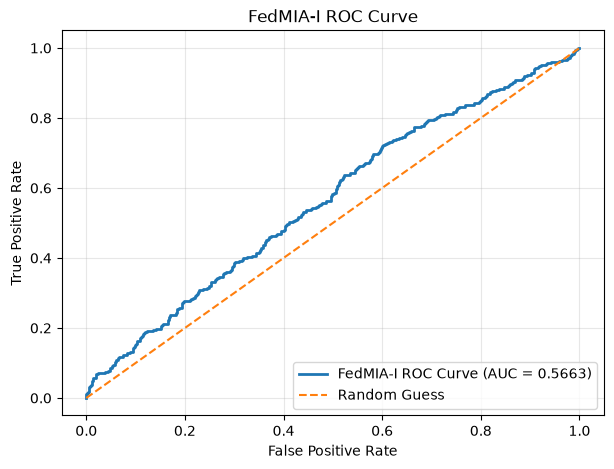

In [40]:
# True labels
attack_labels = (
    [1] * len(member_scores)
    +
    [0] * len(nonmember_scores)
)

# Scores
attack_scores = (
    member_scores
    +
    nonmember_scores
)

# ROC curve
fpr, tpr, thresholds = roc_curve(
    attack_labels,
    attack_scores
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'FedMIA-I ROC Curve (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Guess'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("FedMIA-I ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [41]:
# Classification Report of FedMIA-I

best_f1 = 0
best_threshold = None

for threshold in thresholds:
    preds = (np.array(attack_scores) >= threshold).astype(int)
    f1 = f1_score(attack_labels, preds)

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Best F1:", best_f1)

best_preds = (
    np.array(attack_scores) >= best_threshold
).astype(int)

print(
    classification_report(
        attack_labels,
        best_preds,
        digits=4
    )
)

Best threshold: -7.454588066270475
Best F1: 0.66711140760507
              precision    recall  f1-score   support

           0     1.0000    0.0020    0.0040       500
           1     0.5005    1.0000    0.6671       500

    accuracy                         0.5010      1000
   macro avg     0.7503    0.5010    0.3356      1000
weighted avg     0.7503    0.5010    0.3356      1000



# FedMIA-II Pipeline

In [24]:
# ============================================================
# FedMIA-II Attack Pipeline (New IID FL Notebook)
# ============================================================

# Core Idea:
# cosine_similarity(patient_gradient, client_update)

# where:
#
# client_update =
# local_weights - global_weights_before_round
#
# patient_gradient =
# gradient of one patient loss w.r.t. global model parameters

# High similarity =>
# patient likely belongs to target client

# Step 1 — Flatten model weights into vector

In [54]:
def flatten_weights(weights_dict):

    flat_vector = []

    for key in weights_dict:
        flat_vector.append(
            weights_dict[key].flatten()
        )

    flat_vector = torch.cat(flat_vector)

    return flat_vector

# Step 2 — Compute client update vector

In [43]:
def get_client_update(round_num, cid):

    global_weights = all_round_global_weights_before[round_num]
    local_weights = all_round_local_weights[round_num][cid - 1]

    global_vec = flatten_weights(global_weights)
    local_vec = flatten_weights(local_weights)

    #update_vec = local_vec - global_vec
    update_vec = global_vec - local_vec

    return update_vec

# Step 3 — Test client update

In [44]:
update = get_client_update(0, 50)

print(update.shape)

torch.Size([65409])


# Step 4 — Compute patient gradient vector

In [28]:
# For one patient:

#forward pass
#compute BCE loss
#backward pass
#flatten gradients

In [45]:
def get_patient_gradient(
    patient_x,
    patient_y,
    round_num,
    input_dim
):

    model = MLP(input_dim)

    model.load_state_dict(
        all_round_global_weights_before[round_num]
    )

    model.train()

    criterion = nn.BCELoss()

    x_tensor = torch.tensor(
        patient_x,
        dtype=torch.float32
    ).unsqueeze(0)

    y_tensor = torch.tensor(
        [[patient_y]],
        dtype=torch.float32
    )

    model.zero_grad()

    output = model(x_tensor)

    loss = criterion(
        output,
        y_tensor
    )

    loss.backward()

    grad_list = []

    for param in model.parameters():
        grad_list.append(
            param.grad.flatten()
        )

    grad_vector = torch.cat(
        grad_list
    )

    return grad_vector

# Step 5 — Test patient gradient

In [55]:
input_dim = X_test_scaled.shape[1]

grad = get_patient_gradient(
    member_samples[0],
    member_labels[0],
    round_num=0,
    input_dim=input_dim
)

print(grad.shape)

torch.Size([65409])


# Step 6 — Cosine similarity

In [47]:
def cosine_similarity_score(
    patient_x,
    patient_y,
    round_num,
    cid,
    input_dim
):

    grad_vector = get_patient_gradient(
        patient_x,
        patient_y,
        round_num,
        input_dim
    )

    update_vector = get_client_update(
        round_num,
        cid
    )

    similarity = F.cosine_similarity(
        grad_vector.unsqueeze(0),
        update_vector.unsqueeze(0)
    )

    return similarity.item()

# Step 7 — Test one patient across all clients

In [48]:
patient_x = member_samples[0]
patient_y = member_labels[0]

similarities = {}

for cid in clients_scaled:

    sim = cosine_similarity_score(
        patient_x,
        patient_y,
        round_num=0,
        cid=cid,
        input_dim=input_dim
    )

    similarities[cid] = sim

print(similarities)

{1: -0.006841971538960934, 2: 0.04818239063024521, 3: -0.03023834154009819, 4: -0.016046885401010513, 5: 0.05178592726588249, 6: -0.03421417251229286, 7: 0.005445966962724924, 8: -0.04010084271430969, 9: 0.018969383090734482, 10: 0.033264677971601486, 11: 0.021073859184980392, 12: 0.006170771084725857, 13: -0.0007408661767840385, 14: 0.01589187979698181, 15: -0.02157154679298401, 16: -0.0053681302815675735, 17: 0.017440833151340485, 18: 0.010526718571782112, 19: 0.05726148933172226, 20: 0.04270388185977936, 21: -0.017969351261854172, 22: -0.03722638636827469, 23: -0.015360461547970772, 24: 0.04008280485868454, 25: 0.023873846977949142, 26: -0.02220604568719864, 27: -0.02301134541630745, 28: -0.043396152555942535, 29: -0.032685257494449615, 30: 0.05048959702253342, 31: 0.006824515759944916, 32: -0.06956730782985687, 33: -0.03453308343887329, 34: 0.002115259412676096, 35: 0.02638896182179451, 36: 0.027890173718333244, 37: 0.002264422830194235, 38: -0.029700128361582756, 39: -0.0313238166

# Step 8 — Compute FedMIA-II score (single round)

In [56]:
def compute_fedmiai2_score(
    patient_x,
    patient_y,
    round_num,
    target_client,
    input_dim
):

    similarities = {}

    for cid in clients_scaled:

        sim = cosine_similarity_score(
            patient_x,
            patient_y,
            round_num,
            cid,
            input_dim
        )

        similarities[cid] = sim

    target_sim = similarities[target_client]

    reference_sims = [
        similarities[cid]
        for cid in similarities
        if cid != target_client
    ]

    score = (
        target_sim - np.mean(reference_sims)
    ) / np.std(reference_sims)

    return score

# Step 9 — Test one patient single round

In [50]:
score = compute_fedmiai2_score(
    member_samples[0],
    member_labels[0],
    round_num=0,
    target_client=50,
    input_dim=input_dim
)

print(score)

-0.17105633411517418


# Step 10 — Multi-round FedMIA-II

In [51]:
def compute_multiround_fedmiai2_score(
    patient_x,
    patient_y,
    target_client,
    input_dim,
    num_rounds=20
):

    round_scores = []

    for round_num in range(num_rounds):

        score = compute_fedmiai2_score(
            patient_x,
            patient_y,
            round_num,
            target_client,
            input_dim
        )

        round_scores.append(score)

    final_score = np.mean(round_scores)

    return final_score

# Step 11 — Compute member scores

In [52]:
member_scores_2 = []

for i in range(500):

    score = compute_multiround_fedmiai2_score(
        member_samples[i],
        member_labels[i],
        target_client=50,
        input_dim=input_dim,
        num_rounds=20
    )

    member_scores_2.append(score)

# Step 12 — Compute non-member scores

In [57]:
nonmember_scores_2 = []

for i in range(500):

    score = compute_multiround_fedmiai2_score(
        nonmember_samples[i],
        nonmember_labels[i],
        target_client=50,
        input_dim=input_dim,
        num_rounds=20
    )

    nonmember_scores_2.append(score)

In [58]:
print("Member mean:", np.mean(member_scores_2))
print("Non-member mean:", np.mean(nonmember_scores_2))

Member mean: 0.3042053421052359
Non-member mean: 0.05604657771514541


Attack AUC

In [59]:
attack_labels = (
    [1] * len(member_scores_2)
    +
    [0] * len(nonmember_scores_2)
)

attack_scores = (
    member_scores_2
    +
    nonmember_scores_2
)


attack_auc = roc_auc_score(
    attack_labels,
    attack_scores
)

print("FedMIA-II Attack AUC:", attack_auc)

FedMIA-II Attack AUC: 0.5741240000000001


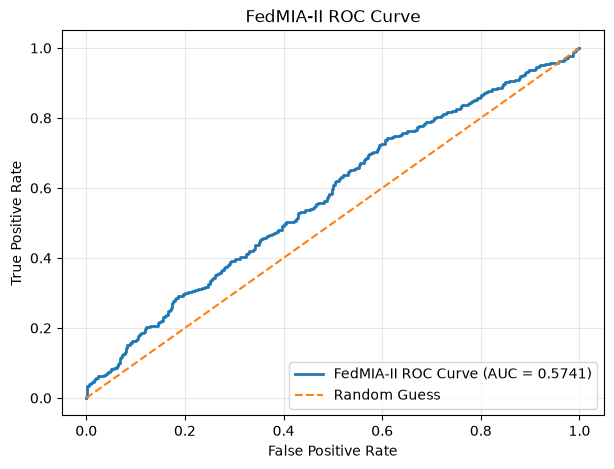

In [62]:
# ROC curve
fpr, tpr, thresholds = roc_curve(
    attack_labels,
    attack_scores
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'FedMIA-II ROC Curve (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Guess'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("FedMIA-II ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [61]:
# CLassification report of FedMIA Attack-II

best_f1 = 0
best_threshold = None

for threshold in thresholds:
    preds = (np.array(attack_scores) >= threshold).astype(int)
    f1 = f1_score(attack_labels, preds)

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Best F1:", best_f1)

best_preds = (
    np.array(attack_scores) >= best_threshold
).astype(int)

print(
    classification_report(
        attack_labels,
        best_preds,
        digits=4
    )
)

Best threshold: -3.0804816024669597
Best F1: 0.66711140760507
              precision    recall  f1-score   support

           0     1.0000    0.0020    0.0040       500
           1     0.5005    1.0000    0.6671       500

    accuracy                         0.5010      1000
   macro avg     0.7503    0.5010    0.3356      1000
weighted avg     0.7503    0.5010    0.3356      1000



In [63]:
fed_results = pd.DataFrame({
    'Paradigm': [
        'Federated',
        'Federated'
    ],

    'Model': [
        'MLP',
        'MLP'
    ],

    'Data': [
        '(IID)',
        '(IID)'
    ],

    'Mortality AUC': [
        0.765,
        0.765
    ],

    'Attack Type': [
        'FedMIA-I',
        'FedMIA-II'
    ],

    'Attack AUC': [
        0.566,
        0.574
    ]
})

fed_results

,Paradigm,Model,Data,Mortality AUC,Attack Type,Attack AUC
0,Federated,MLP,(IID),0.765,FedMIA-I,0.566
1,Federated,MLP,(IID),0.765,FedMIA-II,0.574
